
# Laboratorium 1: Poznaj swoje dane


W ramach naszych zajęć będziemy przechodzić przez kolejne warstwy systemu NLP:

`dane → baseline → reprezentacja → transformer → IE/NER → LLM → retrieval → RAG → ewaluacja`

Ten sam sposób myślenia będzie wracał na każdych zajęciach:

1. **pytanie badawcze,**
2. **hipoteza,**
3. **eksperyment,**
4. **metryka,**
5. **analiza błędów,**
6. **wniosek.**


> **Pytanie badawcze na dziś:** zanim wybierzemy model, czy wiemy, na jakich danych będziemy go trenować i testować?




## Po tych zajęciach student potrafi:

- wykonać podstawowy EDA dla danych tekstowych;
- sprawdzić rozkład klas i długości tekstów;
- wykryć puste rekordy, duplikaty (i potencjalne duplikaty);
- sprawdzić, czy między `train`, `validation` i `test` nie ma wycieku danych (data leakage);
- zbudować powtarzalny split i zapisać jego manifest;
- przygotować prostą kartę opisową zbioru;
- odróżnić problem modelu od problemu danych.

### Zasada na dziś

> **Podejrzanie dobry wynik jest powodem do szczegółowej ewaluacji, nie do świętowania.**



## Dane: PolEmo 2.0 / KLEJ

Pracujemy na polskich recenzjach konsumenckich z zadania [PolEmo 2.0](https://huggingface.co/datasets/allegro/klej-polemo2-in) w benchmarku KLEJ.

Klasy sentymentu:

- `plus`: pozytywny,
- `minus`: negatywny,
- `zero`: neutralny,
- `amb`: niejednoznaczny.

Repozytorium danych:  
https://huggingface.co/datasets/allegro/klej-polemo2-in

Publikacja KLEJ:  
https://arxiv.org/abs/2005.00630

Licencja zbioru na Hugging Face: CC BY-SA 4.0.

> **Ważne:** w projekcie produkcyjnym sprawdzamy nie tylko jakość danych, ale również ich pochodzenie, licencję, warunki redystrybucji i możliwość przetwarzania.



## Ustawienia wstępne

Do laboratorium wystarczy klasyczny stack Data Science.

Jeśli pracują Państwo w izolowanym / nowym środowisku:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow
```

In [9]:

from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

ARTIFACTS = Path("../artifacts")
ARTIFACTS.mkdir(exist_ok=True)



## 1. Pobranie danych

Ładujemy oficjalne splity. Podział danych jest częścią eksperymentu, a nie technicznym szczegółem.


In [10]:
# TODO: ładowanie splitów datasetu (pliki train.csv, valid.csv, test.csv w repozytorium HF)
#
# Po tej komórce MUSZĄ istnieć (używają ich dalsze komórki):
#   URLS        - dict: split -> URL pliku
#   splits      - dict: "train" / "validation" / "test" -> DataFrame z kolumnami text, target, split
#   train_df, val_df, test_df
#   SPLIT_SIZES - dict: split -> liczba rekordów
#   CLASSES     - lista klas
#   LABEL_MAP   - dict: oryginalna etykieta -> plus / minus / zero / amb

# Uwaga: nazwy kolumn w pliku źródłowym mogą różnić się od nazw używanych w notatniku.

BASE_URL= "https://huggingface.co/datasets/allegro/klej-polemo2-in/resolve/main/"
URLS = {
    "train": BASE_URL + "train.csv",
    "validation": BASE_URL + "valid.csv",
    "test": BASE_URL + "test.csv",
}

LABEL_MAP = {
    "__label__meta_plus_m": "plus",
    "__label__meta_minus_m": "minus",
    "__label__meta_zero": "zero",
    "__label__meta_amb": "amb",
}

splits = {}

for split_name, url in URLS.items():
    df = pd.read_csv(url)
    df = df.rename(columns={"sentence": "text"})
    df["target"] = df["target"].map(LABEL_MAP)
    df["split"] = split_name
    splits[split_name] = df

train_df, val_df, test_df = splits["train"], splits["validation"], splits["test"]

SPLIT_SIZES = {name: len(df) for name, df in splits.items()}
CLASSES = sorted(LABEL_MAP.values())


# Zadanie 1: Sanity check danych

Zanim zrobią Państwo coś bardziej zaawansowanego, proszę odpowiedzieć na pytanie:

1. Jakie kolumny zawiera zbiór?
2. Jaki jest typ każdej kolumny?
3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy?
4. Czy występują wartości brakujące?
5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? Jeśli nazwy etykiet są nieczytelne, proszę zdefiniować `LABEL_MAP` (np. `__label__meta_plus_m` → `plus`) i zapisać go w manifeście.
6. Czy są rekordy z pustym albo bardzo krótkim tekstem?

### Do wykonania

Proszę uzupełnić komórkę poniżej. Wynik powinien zawierać jedną małą tabelę ewaluacyjną per split.


In [11]:
# TODO: sanity check dla train / validation / test.
#
# Minimalne kolumny tabeli:
# - split
# - rows
# - columns
# - missing_text
# - missing_target
# - unique_labels
#
# Wskazówka:
# display(df.isna().sum())
# display(df["target"].value_counts(dropna=False))

# MIEJSCE NA KOD

audit_rows = []

for split_name, df in splits.items():
    audit_rows.append({
        "split": split_name,
        "rows": len(df),
        "columns": df.columns.tolist(),
        "columns_dtypes": df.dtypes.to_dict(),
        "missing_text": df["text"].isna().sum(),
        "missing_target": df["target"].isna().sum(),
        "unique_labels": df["target"].unique(),
        "short_text_rows": df[df["text"].str.len() < 50].shape[0]
    })


pd.DataFrame(audit_rows)

,split,rows,columns,columns_dtypes,missing_text,missing_target,unique_labels,short_text_rows
0,train,5783,"[text, target, split]","{'text': str, 'target': str, 'split': str}",0,0,"[plus, minus, amb, zero]",2
1,validation,723,"[text, target, split]","{'text': str, 'target': str, 'split': str}",0,0,"[minus, plus, zero, amb]",0
2,test,722,"[text, target, split]","{'text': str, 'target': str, 'split': str}",0,0,"[minus, zero, plus, amb]",1


### Wnioski z sanity checku

1. **Kolumny:** plik źródłowy ma tylko 2 kolumny: `sentence` (tekst recenzji) i `target` (etykieta). Po wczytaniu zmieniamy `sentence` → `text` i dodajemy `split`, więc mamy `text, target, split`.
2. **Typy:** wszystkie kolumny są tekstowe (`str`,  `StringDtype` w pandas).
3. **Liczba rekordów:** train = 5783, validation = 723, test = 722 (razem 7228). Zgadza się z kartą zbioru na HF (5.78k / 723 / 722).
4. **Braki:** nie ma `NaN` w `text` ani w `target` w żadnym splicie i nie ma też tekstów pustych ani złożonych z samych spacji. `LABEL_MAP` pokrywa wszystkie etykiety, bo po mapowaniu `missing_target = 0`.
5. **Etykiety:** każdy split ma ten sam zbiór 4 wartości (`__label__meta_plus_m / minus_m / zero / amb`). W celu poprawienia ich czytelności `LABEL_MAP` mapuje je na `plus / minus / zero / amb`
6. **Krótkie teksty:** poniżej 50 znaków jest tylko 1 rekord: tekst `"P"` z etykietą `amb`.


## Hipoteza 1

Czy dane są zbalansowane?

Zanim sporządzą Państwo wykres, proszę sformułować hipotezę.

> Przykład formy: „Spodziewam się, że amb będzie klasą dominującą, ponieważ często w recenzje zawierja zarówno elementy poztywne i negatywne.”


# Zadanie 2: Rozkład klas

Proszę policzyć:

- liczebność klas,
- udział procentowy klas,
- rozkład osobno dla `train`, `validation`, `test`.

Następnie proszę odpowiedzieć:

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?
2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?
3. Czy rozkłady klas między splitami są podobne?


In [12]:

# TODO: tabela rozkładu klas dla każdego splitu

# MIEJSCE NA KOD

counts = pd.concat(
    {name: df["target"].value_counts() for name, df in splits.items()},
    axis=1
).T

percentages = counts.div(counts.sum(axis=1), axis=0) * 100

display(counts)
display(percentages.round(1))

target,minus,plus,amb,zero
train,2194,1568,1050,971
validation,271,209,116,127
test,300,197,108,117


target,minus,plus,amb,zero
train,37.9,27.1,18.2,16.8
validation,37.5,28.9,16.0,17.6
test,41.6,27.3,15.0,16.2


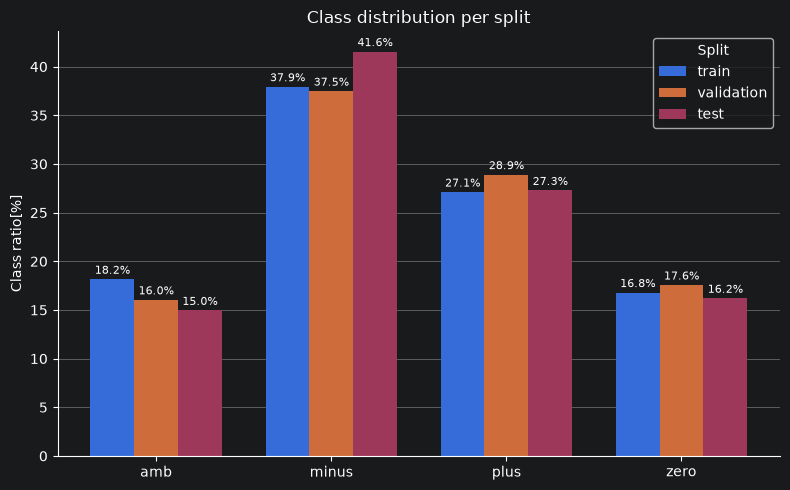

In [13]:

# TODO: wykres rozkładu klas

percentages = pd.concat(
    {name: df["target"].value_counts(normalize=True) * 100 for name, df in splits.items()},
    axis=1
).reindex(CLASSES)

x = np.arange(len(CLASSES))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

for i, split_name in enumerate(["train", "validation", "test"]):
    bars = ax.bar(
        x + (i - 1) * width,
        percentages[split_name],
        width=width,
        label=split_name,
    )
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel("Class ratio[%]")
ax.set_title("Class distribution per split")
ax.legend(title="Split")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="lightgray", linewidth=0.5, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

1. **Accuracy nie wystarczy.** Klasy są niezbalansowane (`minus` ok. 38–42%, `zero` i `amb` ok. 15–18%), więc model może mieć przyzwoite accuracy, a słabo radzić sobie z rzadszymi klasami. Lepiej patrzeć też na macro-F1 i wyniki per klasa.

2. **Naiwny klasyfikator** zawsze wybierający `minus` osiągnąłby na teście accuracy około 41.6% (300/722).

3. **Rozkłady są podobne**, różnice między splitami nie przekraczają kilku punktów procentowych. Jedynie w teście jest nieco więcej `minus` (41.6% wobec 37.9% w train), a mniej `amb`.


# Zadanie 3: Jak wygląda „typowy tekst”?

Długość tekstu jest jednym z pierwszych parametrów, które warto sprawdzić.

Do wyświetlania tekstu proszę dodać cechy:

- `n_chars`: liczba znaków,
- `n_words`: liczba słów (regex `\w+`) oraz `n_words_split` (`split()` po białych znakach),
- `n_lines`: liczba linii.

Proszę policzyć co najmniej:

- minimum,
- medianę,
- średnią,
- 90. percentyl,
- 95. percentyl,
- 99. percentyl,
- maksimum.

Następnie proszę obejrzeć (i zanotować wnioski z obserwacji):

- 5 najkrótszych tekstów,
- 5 najdłuższych tekstów.

### Pytania

- Czy ekstremalnie długi dokument zawsze jest błędem?
- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

In [14]:
all_df = pd.concat(splits.values(), ignore_index=True)
# TODO: do dodania n_chars, n_words, n_words_split, n_lines.

all_df["n_chars"] = all_df["text"].str.len()
all_df["n_words"] = all_df["text"].str.findall(r"\w+").str.len()
all_df["n_words_split"] = all_df["text"].str.split().str.len()
all_df["n_lines"] = all_df["text"].str.count("\n") + 1

all_df.head()

,text,target,split,n_chars,n_words,n_words_split,n_lines
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,plus,train,681,105,126,1
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train,663,97,107,1
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train,304,41,50,1
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train,917,127,156,1
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train,570,89,109,1


In [15]:
# TODO: tabela statystyk długości

cols = ["n_chars", "n_words", "n_words_split", "n_lines"]

stats = (
    all_df[cols]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .loc[["min", "50%", "mean", "90%", "95%", "99%", "max"]]
    .rename(index={"50%": "median", "90%": "p90", "95%": "p95", "99%": "p99"})
)
stats



,n_chars,n_words,n_words_split,n_lines
min,1.000000,1.000000,1.000000,1.0
median,696.000000,102.000000,121.000000,1.0
mean,777.012313,114.322634,136.319175,1.0
p90,1294.000000,191.000000,228.000000,1.0
p95,1605.650000,242.000000,288.650000,1.0
p99,2335.190000,352.730000,414.730000,1.0
max,5391.000000,774.000000,987.000000,1.0


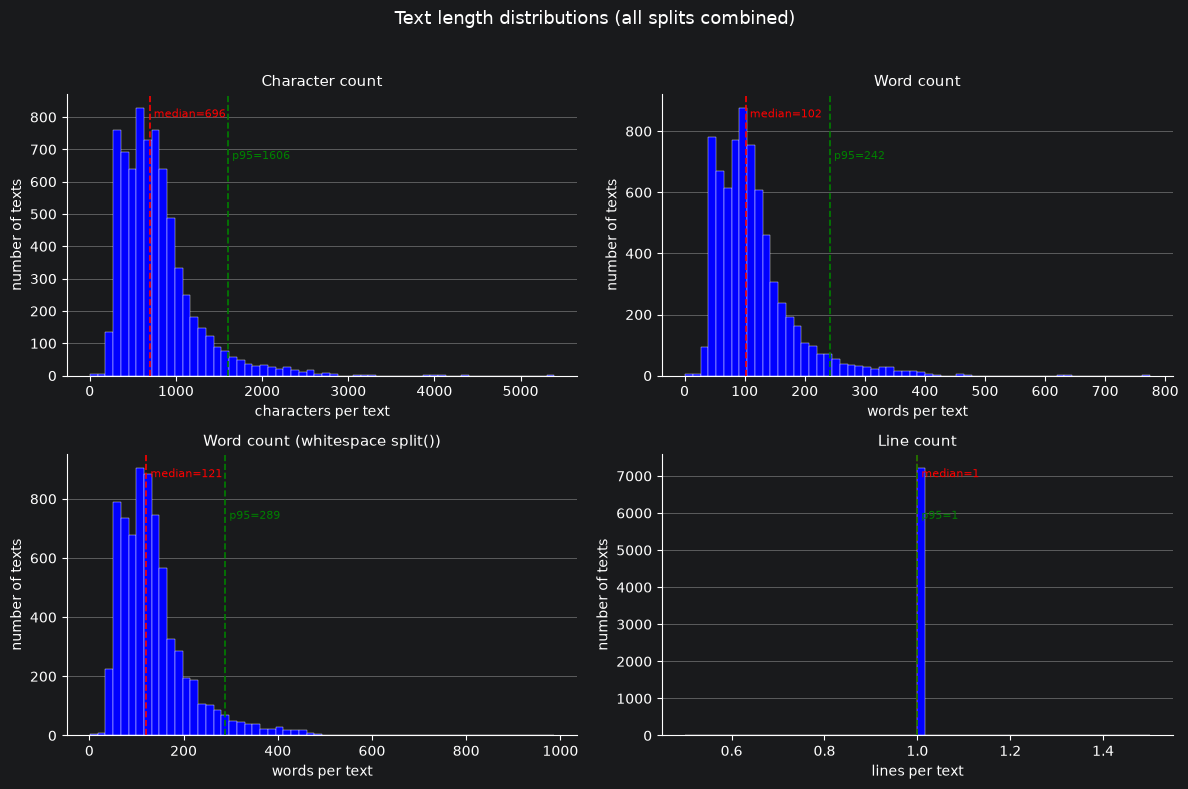

In [16]:
# TODO: histogram długości tekstów


features = ["n_chars", "n_words", "n_words_split", "n_lines"]
titles = {
    "n_chars": "Character count",
    "n_words": "Word count",
    "n_words_split": "Word count (whitespace split())",
    "n_lines": "Line count",
}
xlabels = {
    "n_chars": "characters per text",
    "n_words": "words per text",
    "n_words_split": "words per text",
    "n_lines": "lines per text",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    data = all_df[feature]
    median = data.median()
    p95 = data.quantile(0.95)

    ax.hist(data, bins=60, color="blue", edgecolor="white", linewidth=0.3)

    ax.axvline(median, color="red", linestyle="--", linewidth=1.2)
    ax.axvline(p95, color="green", linestyle="--", linewidth=1.2)

    ymax = ax.get_ylim()[1]
    ax.text(median, ymax * 0.95, f" median={median:.0f}", color="red",
             fontsize=8, va="top", ha="left")
    ax.text(p95, ymax * 0.80, f" p95={p95:.0f}", color="green",
             fontsize=8, va="top", ha="left")

    ax.set_title(titles[feature], fontsize=11)
    ax.set_xlabel(xlabels[feature])
    ax.set_ylabel("number of texts")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="lightgray", linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

fig.suptitle("Text length distributions (all splits combined)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [17]:
# TODO: skrajne obserwacje

all_df.sort_values("n_words_split", ascending=True).head(5)


,text,target,split,n_chars,n_words,n_words_split,n_lines
4476,P,amb,train,1,1,1,1
7041,Marka Baccarat Hotels & Res o,zero,test,29,5,6,1
7095,W grudniu czterogwiazdkowy Hotel Korona Spa & Wel l,zero,test,51,8,9,1
4310,"Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o",minus,train,47,10,14,1
4129,Justyna Kaczorowska objęła stanowisko dyrektora marketingu w polskim oddziale Vienna International Hotels & Res o,zero,train,113,14,15,1


**Najkrótsze teksty** są to niekompletne, nieukończone recenzje:
- `"P"` (1 znak, etykieta `amb`): treści nie ma, etykieta jest nieweryfikowalna.
- `"... Hotels & Res o"`, `"... & aut o"`, `"... Spa & Wel l"`, `"... & Gwa r"`: tekst urywa się zawsze tuż po znaku `&`, a ostatnie słowo jest rozcięte spacją.

In [18]:
all_df.sort_values("n_words_split", ascending=False).head(5)

,text,target,split,n_chars,n_words,n_words_split,n_lines
3200,"Wybór sylwestrowego pakietu w tym hotelu za gigantyczne pieniądze ( jak na zaproponowane warunki i "" atrakcje "" ) to jeden z naszych największych błędów . K...",minus,train,5391,774,987,1
4870,Wykupiła m w państwa Hotelu pobyt świąteczny od dnia 23 . 12 - 26 . 12 . 2016r . dla 3 osób dorosłych i dwóch kotków . Rezerwacji dokonała m w miesiącu paźd...,minus,train,4352,630,766,1
4492,"Właśnie wrócili śmy z "" weekendowego "" pobytu w Amaxie , skusili śmy sie akurat na ten hotel po przeczytaniu pozytywnych opinii . Wolna była willa 4 osobowa...",minus,train,4107,641,759,1
5531,"W hotelu gościmy regularnie od pięciu lat , magiczne miejsce nad klimatycznym jeziorem z dobra kuchnia oparta o lokalne produkty z masą ryb . Spory aquapark...",minus,train,4023,620,745,1
6350,Ten Hotel to jest kpina z klienta . Hotel jedynie ładnie wygląda na zdjęciach i z daleka . Zdjęcia były robione dawno temu jak powstał ten hotel i nie aktua...,minus,validation,3917,637,708,1


**Najdłuższe teksty:** wszystkie 5 to negatywne recenzje hoteli (3900 do 5391 znaków), czyli szczegółowe opisy reklamacji.

### Odpowiedzi

**1. Czy ekstremalnie długi dokument zawsze jest błędem?**

Nie. Najdłuższe teksty to zwykłe, spójne recenzje, w których klienci szczegółowo opisują swoje reklamacje. Warto je przejrzeć, bo czasem kryją się tam sklejone rekordy, ale sama długość nie jest błędem.

**2. Co długość zmienia w tokenizacji, batchowaniu i chunkingu?**
- *Tokenizacja:* modele typu BERT mają limit 512 tokenów. Już p95 to około 290 słów, a tokenizator dzieli polskie słowa na kilka części, więc część tekstów zostanie ucięta. Najczęściej będą to długie recenzje `minus`, a ucięty zostanie koniec, gdzie zwykle jest ocena końcowa.
- *Batchowanie:* jeden bardzo długi tekst wymusza padding całego batcha. Pomaga dynamiczny padding albo grupowanie tekstów po długości.
- *Chunking:* długie dokumenty trzeba dzielić na fragmenty. Etykieta dotyczy jednak całego tekstu, a nie fragmentu. Fragmenty jednego dokumentu muszą też trafić do tego samego splitu.

**3. Dlaczego `n_words_split` ≠ `n_words`?**

Interpunkcja jest oddzielona spacjami (`"lekarz . Bardzo"`), więc `split()` liczy każdą kropkę i przecinek jako słowo, a `\w+` je pomija. Dlatego `n_words_split` jest większe prawie zawsze. Do tego część końcówek jest odcięta od słów (`"Wykupiła m"`, `"wrócili śmy"`). Oznacza to, że tekst był już wcześniej stokenizowany i nie jest surowym tekstem.


# Zadanie 4: Szum danych

Tekst naturalny nie jest sterylny.

Proszę sprawdzić, ile rekordów zawiera co najmniej jeden z poniższych elementów:

- URL,
- adres e-mail,
- sekwencję wielu wykrzykników lub znaków zapytania,
- dużo WIELKICH LITER,
- znaki nowej linii,
- tekst krótszy niż 20 znaków.

Proszę nie usuwać ich automatycznie!

> Najpierw wykrywamy zjawisko. Potem decydujemy, czy jest błędem, sygnałem czy częścią danych.

Proszę też sprawdzić, czy którakolwiek flaga szumu jest skorelowana z etykietą. Czy to sygnał, artefakt, czy shortcut?

In [19]:
# TODO: proszę obliczyć poniższe flagi bool
#
# has_url, has_email, has_punct_burst, has_newline, is_very_short, high_uppercase
#
# Proponowany próg high_uppercase: uppercase_ratio > 0.5,
# zaleca się eksperyment z tym progiem.
#
# UWAGA: w tym zbiorze interpunkcja jest oddzielona spacjami (np. "! ! !"),
# więc prosty wzorzec [!?]{2,} jej nie wykryje.

flags = ["has_url", "has_email", "has_punct_burst", "has_newline", "is_very_short", "high_uppercase"]

URL_REGEX = r"https? ?: ?/|www ?\. ?\S+ ?\."
EMAIL_REGEX = r"\S+ ?@ ?\S+ ?\. ?[a-z]{2,}\b"


text = all_df["text"]
all_df["has_url"] = text.str.contains(URL_REGEX, case=False)
all_df["has_email"] = text.str.contains(EMAIL_REGEX, case=False)
all_df["has_punct_burst"] = text.str.contains(r"[!?](?:\s*[!?]){2,}", case=False)
all_df["has_newline"] = text.str.contains("\n", case=False)
all_df["is_very_short"] = text.str.len() < 20
n_upper = text.str.count(r"\p{Lu}")
n_letters = text.str.count(r"\p{L}")
all_df["uppercase_ratio"] = n_upper / n_letters.replace(0, 1)
all_df["high_uppercase"] = all_df["uppercase_ratio"] > 0.5

any_noise = all_df[flags].any(axis=1)
display(all_df[flags].sum().to_frame("count"))
print("Number of records with at least one flag:", any_noise.sum(), f"({any_noise.mean():.1%})")

for f in flags:
    if all_df[f].any():
        print(f'{f}')
        display(pd.crosstab(all_df[f], all_df["target"], normalize="index"))
        display(pd.crosstab(all_df[f], all_df["target"]))

,count
has_url,11
has_email,5
has_punct_burst,657
has_newline,0
is_very_short,1
high_uppercase,10


Number of records with at least one flag: 676 (9.4%)
has_url


target,amb,minus,plus,zero
has_url,,,,
False,0.176528,0.382985,0.273244,0.167244
True,0.000000,0.090909,0.181818,0.727273


target,amb,minus,plus,zero
has_url,,,,
False,1274,2764,1972,1207
True,0,1,2,8


has_email


...

target,amb,minus,plus,zero
is_very_short,,,,
False,0.176145,0.382593,0.273142,0.16812
True,1.000000,0.000000,0.000000,0.00000


target,amb,minus,plus,zero
is_very_short,,,,
False,1273,2765,1974,1215
True,1,0,0,0


high_uppercase


target,amb,minus,plus,zero
high_uppercase,,,,
False,0.176365,0.382377,0.273067,0.168191
True,0.100000,0.500000,0.300000,0.100000


target,amb,minus,plus,zero
high_uppercase,,,,
False,1273,2760,1971,1214
True,1,5,3,1


Najczęstszą flagą jest `has_punct_burst` (808 rekordów, ok. 11%). Wyraźnie wiąże się z klasą minus (69% wobec 35% w całym zbiorze), a w zero prawie nie występuje. To naturalny sygnał emocji, ale model może potraktować go jako shortcut i błędnie klasyfikować pozytywne teksty z wykrzyknikami. `has_url` występuje głównie w klasie zero (8 z 11). To raczej artefakt źródła (teksty informacyjne), a nie cecha sentymentu. Pozostałe flagi są zbyt rzadkie (n ≤ 10), żeby oceniać ich związek z etykietą. `has_newline` nie występuje wcale, bo teksty zostały spłaszczone.


# Zadanie 5: Duplikaty

Duplikat w danych treningowych nie zawsze jest problemem. Jednak duplikat między zbiorami train i test może zafałszować wyniki.

Zaczniemy od dwóch wersji tekstu:

1. `text_raw`: oryginał,
2. `text_norm`: wersja używana wyłącznie do oceny duplikatów.

Normalizacja:

- Unicode NFKC,
- lowercase,
- redukcja białych znaków,
- trim.

> Nie usuwamy interpunkcji i nie robimy agresywnego preprocessingu.


In [20]:
# TODO:
# preprocessing

# TODO:
# 1. jakie dokładne duplikaty text_raw,
# 2. jakie duplikaty text_norm,
# 3. 10 przykładowych grup duplikatów,
# 4. czy ten sam text_norm występuje w więcej niż jednym splicie?

# MIEJSCE NA KOD
all_df["text_raw"] = all_df["text"]
all_df["text_norm"] = (
    all_df["text_raw"]
    .str.normalize("NFKC")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

dup_raw = all_df["text_raw"].duplicated(keep=False)
dup_norm = all_df["text_norm"].duplicated(keep=False)

print(f'Duplicated records (raw): {dup_raw.sum()}')
print(f'Duplicated records (norm): {dup_norm.sum()}')



groups = (
    all_df[dup_norm]
    .groupby("text_norm")
    .agg(
        n=("text_norm", "size"),
        splits=("split", lambda s: sorted(set(s))),
        labels=("target", lambda s: sorted(set(s))),
    )
    .sort_values("n", ascending=False)
)
display(groups.head(10))


cross_split = groups[groups["splits"].str.len() > 1]
print("Groups present in more than on split:", len(cross_split))
print("Groups with different labels for the same text :", (groups["labels"].str.len() > 1).sum())

Duplicated records (raw): 0
Duplicated records (norm): 0


,n,splits,labels
text_norm,,,


Groups present in more than on split: 0
Groups with different labels for the same text : 0


Zbiór nie zawiera dokładnych duplikatów ani przed normalizacją, ani po niej, więc nie ma wycieku między splitami przez identyczne teksty. Prawdopodobnie zbiór był deduplikowany przy tworzeniu benchmarku.


## Funkcja `audit_split_leakage`

Proszę napisać funkcję:

```python
audit_split_leakage(df, text_col="text_norm", split_col="split")
```

która zwróci rekordy występujące w więcej niż jednym splicie.

W wyniku chcemy co najmniej:

- tekst / fingerprint,
- liczbę wystąpień,
- listę splitów,
- etykiety.

To będzie pierwszy element naszej semestralnej biblioteki ewaluacyjnej.

In [21]:

def audit_split_leakage(df, text_col="text_norm", split_col="split"):
    for col in (text_col, split_col):
        if col not in df.columns:
            raise ValueError(f"Column {col!r} not found in DataFrame.Available columns: {df.columns.tolist()}")

    leaks = (
        df.groupby(text_col)
        .agg(
            n=(text_col, "size"),
            n_splits=(split_col, "nunique"),
            splits=(split_col, lambda s: sorted(set(s))),
            labels=("target", lambda s: sorted(set(s))),
        )
        .query("n_splits > 1")
        .sort_values("n", ascending=False)
        .reset_index()
    )
    leaks.insert(0, "fingerprint", leaks[text_col].map(
        lambda t: hashlib.sha256(t.encode("utf-8")).hexdigest()
    ))
    return leaks


audit_split_leakage(df=all_df, text_col="text_norm", split_col="split")

,fingerprint,text_norm,n,n_splits,splits,labels



# Zadanie 6: Prawie duplikaty

Exact match nie wystarczy.

Przykład:

- `Świetny hotel. Polecam!`
- `Świetny hotel - polecam!!!`

Dla człowieka to prawie ten sam tekst. Hash ich nie połączy.

Na próbce danych proszę zbudować prosty detektor zdań, które są prawie duplikatami:

1. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`,
2. `NearestNeighbors(metric="cosine")`,
3. dla każdego tekstu proszę znaleźć najbliższego **innego** sąsiada (uwaga: przy `n_neighbors=1` sąsiadem jest zwykle ten sam dokument, więc pobierz kilku i pomiń siebie),
4. proszę policzyć podobieństwo jako `1 - cosine_distance`,
5. proszę policzyć pary z podobieństwem np. `>= 0.90`, osobno w obrębie jednego splitu i między splitami.

### Nie chodzi o idealny deduplikator

Celem jest zobaczenie, że decyzja "duplikat / nie duplikat" sama może być problemem modelowym.

In [22]:
# TODO nearest_other_neighbour

# MIEJSCE NA KOD
# j, sim = nearest_other_neighbor(X)
# pairs["cross_split"] = sample["split"].values[pairs["i"]] != sample["split"].values[pairs["j"]]

sample = all_df.reset_index(drop=True)
tfidf_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
X = tfidf_vec.fit_transform(sample["text_norm"])

def nearest_other_neighbor(X, k=5):
    nn = NearestNeighbors(n_neighbors=k, metric="cosine").fit(X)
    dist, idx = nn.kneighbors(X)
    j = np.empty(X.shape[0], dtype=int)
    sim = np.empty(X.shape[0])

    for i in range(X.shape[0]):
        others = idx[i] != i
        j[i] = idx[i][others][0]
        sim[i] = 1 - dist[i][others][0]
    return j, sim


j, sim =  nearest_other_neighbor(X)

pairs = pd.DataFrame({"i": np.arange(len(j)), "j": j, "sim": sim})
pairs["a"], pairs["b"] = np.minimum(pairs.i, pairs.j), np.maximum(pairs.i, pairs.j)
pairs = pairs.drop_duplicates(["a", "b"]).drop(columns=["a", "b"])
pairs["cross_split"] = sample["split"].values[pairs["i"]] != sample["split"].values[pairs["j"]]
pairs.sort_values(by="sim", ascending=False, inplace=True)
pairs.head()

,i,j,sim,cross_split
1344,1344,6642,0.999948,True
3413,3413,5612,0.962757,False
3572,3572,4360,0.943419,False
8,8,6581,0.786939,True
3918,3918,6285,0.740676,True


In [23]:
for th in [0.95, 0.90, 0.80, 0.70]:
    hits = pairs[pairs["sim"] >= th]
    display(hits.head(10))
    print(f"sim >= {th}: {len(hits)} pairs, shared by splits: {hits['cross_split'].sum()}")

,i,j,sim,cross_split
1344,1344,6642,0.999948,True
3413,3413,5612,0.962757,False


sim >= 0.95: 2 pairs, shared by splits: 1


,i,j,sim,cross_split
1344,1344,6642,0.999948,True
3413,3413,5612,0.962757,False
3572,3572,4360,0.943419,False


sim >= 0.9: 3 pairs, shared by splits: 1


,i,j,sim,cross_split
1344,1344,6642,0.999948,True
3413,3413,5612,0.962757,False
3572,3572,4360,0.943419,False


sim >= 0.8: 3 pairs, shared by splits: 1


,i,j,sim,cross_split
1344,1344,6642,0.999948,True
3413,3413,5612,0.962757,False
3572,3572,4360,0.943419,False
8,8,6581,0.786939,True
3918,3918,6285,0.740676,True
752,752,6597,0.718419,True
2061,2061,2596,0.704871,False


sim >= 0.7: 7 pairs, shared by splits: 4


In [24]:
all_df["text_norm"][1344]

'„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i haemophilus influenzae . poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . a ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr kamińska . cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . w celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru ramana . w celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującem

In [25]:
all_df["text_norm"][6642]

'„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i haemophilus influenzae . poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . a ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr kamińska . cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . w celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru ramana . w celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługując


# Zadanie 7: Czy split jest częścią danych?

Proszę porównać:

### A. oficjalny split
`train / validation / test`

### B. naiwny random split
po połączeniu wszystkich rekordów:

```python
train_test_split(..., stratify=target, random_state=42)
```

Nie trenujemy jeszcze modelu docelowego. Chcemy zobaczyć, czy sam sposób dzielenia danych może zmienić eksperyment.

Proszę sprawdzić dla obu wariantów:

- rozkład klas,
- exact duplicates między train/test,
- near-duplicates, jeśli masz czas.

### Pytanie

Czy losowy split jest zawsze metodologicznie poprawny?

Proszę pomyśleć o:

- użytkownikach,
- autorach,
- czasie,
- źródłach,
- dokumentach należących do tej samej sprawy,
- wielu fragmentach pochodzących z jednego dokumentu.


In [26]:
# MIEJSCE NA KOD


def random_stratified_split(df, seed):
    rest, test_idx = train_test_split(
        df.index,
        test_size=SPLIT_SIZES["test"],
        stratify=df["target"],
        random_state=seed,
    )
    train_idx, val_idx = train_test_split(
        rest,
        test_size=SPLIT_SIZES["validation"],
        stratify=df.loc[rest, "target"],
        random_state=seed
    )

    split = pd.Series("train", index=df.index)
    split[val_idx] = "validation"
    split[test_idx] = "test"
    return split


def class_distribution(df, split_col):
    return (
        pd.crosstab(df[split_col], df["target"], normalize="index")
        .reindex(index=["train", "validation", "test"], columns=CLASSES)
        .mul(100)
        .round(1)
    )

all_df["random_split"] =  random_stratified_split(all_df, RANDOM_STATE)
class_distribution(all_df, "random_split")

print("Official split [% class]")
display(class_distribution(all_df, "split"))
print("Random stratified split [% class]")
display(class_distribution(all_df, "random_split"))
print(f"Percentage of records mismatch: "
      f"{(all_df['split'] != all_df['random_split']).mean():.1%}")

Official split [% class]


target,amb,minus,plus,zero
split,,,,
train,18.2,37.9,27.1,16.8
validation,16.0,37.5,28.9,17.6
test,15.0,41.6,27.3,16.2


Random stratified split [% class]


target,amb,minus,plus,zero
random_split,,,,
train,17.6,38.3,27.3,16.8
validation,17.6,38.3,27.4,16.7
test,17.6,38.2,27.3,16.9


Percentage of records mismatch: 34.4%


In [27]:
for col in ["split", "random_split"]:
    train_test = all_df[all_df[col].isin(["train", "test"])]
    leaks =  audit_split_leakage(train_test, text_col="text_norm", split_col=col)

    print(f"{col}: exact duplicates between train/test: {len(leaks)}")

split: exact duplicates between train/test: 0
random_split: exact duplicates between train/test: 0


In [28]:
close = pairs[pairs["sim"] >= 0.8]

for col in ["split", "random_split"]:
    s = all_df[col].to_numpy()
    a = s[close["i"]]
    b = s[close["j"]]
    train_test =  ((a == "train") & (b == "test") | (a == "test") & (b == "train"))
    display(close[train_test])
    print(f'{col}: duplicates train/test (sim >= 0.8) = {train_test.sum()}')

,i,j,sim,cross_split
1344,1344,6642,0.999948,True


split: duplicates train/test (sim >= 0.8) = 1


,i,j,sim,cross_split


random_split: duplicates train/test (sim >= 0.8) = 0


### Odpowiedzi

**Rozkład klas.** Losowy split stratyfikowany ma w każdym splicie prawie te same proporcje (różnice ≤ 0.2 pp). Oficjalny jest mniej równy: test ma 41.6% `minus` przy 37.9% w train, a `amb` 15.0% przy 18.2%.

**Dokładne duplikaty train/test:** 0 w obu wariantach. W zbiorze nie ma dokładnych duplikatów, więc żaden podział ich nie stworzy.


**Prawie duplikaty (sim ≥ 0.8, train/test)**: 1 para w oficjalnym splicie i 0 w losowym (random_state=42), tak samo jak przy 0.9

**Czy losowy split jest zawsze poprawny?** Nie. Zakłada, że rekordy są od siebie niezależne, a w praktyce często nie są:
- *użytkownicy / autorzy:* ta sama osoba pisze kilka recenzji podobnym stylem. W tym zbiorze są dwie wersje jednej recenzji hotelu („Hotel generalnie ok…”), jedna w train, druga w validation. Model uczy się autora, nie sentymentu.
- *czas:* w produkcji model ocenia teksty z przyszłości. Losowy split miesza przeszłość z przyszłością i ukrywa dryf (nowe obiekty, nowe słownictwo, zmiany regulaminu ocen), więc zawyża wynik.
- *źródła:* teksty `zero` to w dużej części fragmenty tekstów prasowych (PAP, raporty GUS), a recenzje pochodzą z portali. Model może rozpoznawać źródło zamiast sentymentu, a losowy split tego nie pokaże.
- *ta sama sprawa:* kilka opinii o tym samym lekarzu lub hotelu dzieli nazwiska i szczegóły. Model może zapamiętać „ten lekarz = dobrze”.
- *fragmenty jednego dokumentu:* w zbiorze są nakładające się fragmenty tych samych notek prasowych (77 i 86 wspólnych słów). Po losowym podziale część dokumentu ląduje w train, a część w teście.

W takich sytuacjach lepszy byłby podział po grupach (autor, obiekt, dokument) albo po czasie, a nie po pojedynczych rekordach.



# Zadanie 8: Eksperyment: wyciek danych potrafi „ulepszyć” model

Teraz użyjemy bardzo prostego klasyfikatora wyłącznie jako sondy diagnostycznej. Nie optymalizujemy hiperparametrów. To będzie temat kolejnego laboratorium.

Pipeline:

`TF-IDF → Logistic Regression`

Najpierw policzymy wynik na poprawnym splicie, a potem celowo zanieczyścimy train przykładami z testu.

### Hipoteza

Proszę sformułować przed uruchomieniem założenie:

> Jak zmieni się accuracy / macro-F1 po wprowadzeniu leakage i dlaczego?
Spodziewam się, że accuracy i macro-F1 wzrosną. W trakcie treningu model zobaczy część rekordów testowych razem z ich etykietami, więc przy ewaluacji na tych rekordach będzie trafiał prawie zawsze. To podniesie wynik na całym teście, choć na rekordach, które nie wyciekły, model nie będzie ani trochę lepszy. Wzrost powinien rosnąć z częścią testu dodaną do treningu.


In [29]:

probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

def evaluate_probe(train_part: pd.DataFrame, test_part: pd.DataFrame):
    probe.fit(train_part["text"], train_part["target"])
    pred = probe.predict(test_part["text"])
    return {
        "accuracy": accuracy_score(test_part["target"], pred),
        "macro_f1": f1_score(test_part["target"], pred, average="macro"),
    }

# Wynik bazowy na oficjalnym splicie:
clean_score = evaluate_probe(train_df, test_df)
clean_score


{'accuracy': 0.832409972299169, 'macro_f1': 0.7874406607152569}

In [30]:
# CELowo tworzymy błędny eksperyment: dokładamy część TESTU do TRAIN.
# Proszę nie robić tego nigdy w prawdziwej ewaluacji!!! :)

def score(model, part):
    pred = model.predict(part["text"])
    return accuracy_score(part["target"], pred), f1_score(part["target"], pred, average="macro")

rows = []
for frac in [0.0, 0.05, 0.10, 0.20, 0.50, 1.0]:
    leaked = test_df.sample(frac=frac, random_state=RANDOM_STATE)
    train_leaky = pd.concat([train_df, leaked], ignore_index=True)
    probe.fit(train_leaky["text"], train_leaky["target"])
    m = test_df.index.isin(leaked.index)
    row = {"leak_fraction": frac}
    row["acc_all"], row["f1_all"] = score(probe, test_df)
    row["acc_leaked"], row["f1_leaked"] = score(probe, test_df[m]) if m.any() else (np.nan, np.nan)
    row["acc_unleaked"], row["f1_unleaked"] = score(probe, test_df[~m]) if (~m).any() else (np.nan, np.nan)
    rows.append(row)

pd.DataFrame(rows)

,leak_fraction,acc_all,f1_all,acc_leaked,f1_leaked,acc_unleaked,f1_unleaked
0,0.00,0.832410,0.787441,NaN,NaN,0.832410,0.787441
1,0.05,0.837950,0.793298,0.916667,0.824472,0.833819,0.791456
2,0.10,0.840720,0.797268,0.944444,0.903195,0.829231,0.787687
3,0.20,0.854571,0.819503,0.951389,0.934320,0.830450,0.791605
4,0.50,0.890582,0.869299,0.952909,0.943915,0.828255,0.796047
5,1.00,0.959834,0.952110,0.959834,0.952110,NaN,NaN



## Analiza

Proszę odpowiedzieć krótko:

1. Jak duża była różnica dla każdej wartości leak_fraction?
2. Czy wynik wzrósł tak mocno, jak było oczekiwane?
3. Dlaczego wyciek przez duplikaty może być bardziej lub mniej szkodliwy zależnie od modelu?
4. Czy wysoki wynik sam w sobie pozwala odróżnić dobry model od błędnej ewaluacji?
5. Jakie testy automatyczne dobrze dodać do pipeline'u danych?
6. Czy wzrost wyniku wynika z zapamiętania wyciekłych rekordów (acc_leaked), czy z poprawy na pozostałych (acc_unleaked)?

### Odpowiedzi

1. **Różnice.** Accuracy rośnie z 0.832 do: 0.838 (+0.6 pp) przy 5%, 0.841 (+0.8 pp) przy 10%, 0.855 (+2.2 pp) przy 20%, 0.891 (+5.8 pp) przy 50% i 0.960 (+12.7 pp) przy 100%.

2. **Czy tak mocno, jak oczekiwano?** Nawet przy pełnym wycieku wynik nie dochodzi do 100%. Jest na poziomie accuracy na samym train (0.958), bo regularyzowany model liniowy nie zapamiętuje każdego rekordu.

3. **Zależność od modelu.** Im bardziej model zapamiętuje dane, tym większa szkoda. kNN czy duży transformer trenowany wiele epok odtworzy wyciekłe rekordy prawie w 100%, a regularyzowany model liniowy mniej. Modele na subwordach lub n-gramach znakowych traktują prawie duplikat niemal jak kopię, więc u nich przeciekają też teksty lekko zmienione.

4. **Czy wysoki wynik coś mówi?** Nie. Przy 50% wycieku wynik 0.891 wygląda po prostu jak lepszy model. Błąd w ewaluacji wykrywa się tylko audytem: sprawdzeniem overlapu train/test, porównaniem validation z testem i wynikami na podzbiorach.

5. **Testy automatyczne w pipeline danych:**
   - schemat i rozmiary splitów zgodne z manifestem (kolumny, liczba rekordów, zbiór etykiet);
   - brak pustych tekstów i etykiet;
   - **0 wspólnych fingerprintów między train, validation i test** (twardy błąd);
   - 0 par między splitami z sim ≥ 0.9; pary 0.7–0.9 trafiają do ręcznego przeglądu;
   - rozkład klas w splitach w ustalonej tolerancji;
   - hash danych zgodny z manifestem (trenujemy na tej wersji, na którą się umówiliśmy);
   - odsetki flag jakości (krótkie teksty, ucięcia) w znanym zakresie: nagły skok oznacza zmianę w źródle.


6. **Skąd wzrost?** Wyłącznie z zapamiętania. `acc_leaked` wynosi 0.92–0.96, a `acc_unleaked` stoi w miejscu (ok. 0.83). Model nie jest lepszy, tylko zna odpowiedzi do części testu.


# Zadanie 9: Dane do kolejnego laboratorium

Na następnych zajęciach będziemy budować baseline'y klasyfikacyjne. Proszę zatem przygotować czysty, wersjonowany artefakt.

### Minimalna polityka czyszczenia

Rekomendujemy:

- usunąć rekordy bez tekstu lub labelu,
- **nie modyfikować** `validation` i `test` (zachować oficjalne rozmiary); duplikaty w tych splitach tylko oznaczyć flagą,
- z `train` usunąć exact duplicates wewnątrz `train` oraz rekordy, których `text_norm` występuje w `validation` lub `test`,
- nie zmieniać treści tekstu bez uzasadnienia,
- nie usuwać "dziwnych" tekstów tylko dlatego, że wyglądają dziwnie,
- każdą operację zapisać w manifeście wraz z liczbą usuniętych rekordów.

### Do zapisania

```text
artifacts/
├── polemo2_clean.parquet
└── splits.json
```

`splits.json` powinien zawierać co najmniej:

- `random_state`,
- liczebności splitów,
- listę klas,
- datę / wersję źródła lub URL,
- opis wykonanych operacji czyszczenia,
- `label_map`,
- liczebności splitów przed i po czyszczeniu,
- SHA-256 pliku `polemo2_clean.parquet`,
- wersje Pythona, pandas i scikit-learn.

In [31]:
# TODO: zdefiniować clean_df zgodnie z polityką czyszczenia
cleaning = []
df = all_df.copy()

# 1. Records without text or target
len_before = len(df)
df = df.dropna(subset=["text", "target"])
df = df[df["text"].str.strip() != ""]
cleaning.append({"op": "drop_missing_text_or_label", "removed": len_before - len(df)})

# Mark exact duplicates within each split (val/test are only flagged)
df["dup_in_split"] = df.duplicated(subset=["split", "text_norm"], keep=False)

train = df[df["split"] == "train"]
eval_df = df[df["split"] != "train"]

# 2. Exact duplicates within train
len_before = len(train)
train = train.drop_duplicates(subset="text_norm", keep="first")
cleaning.append({"op": "drop_exact_dups_within_train", "removed": len_before - len(train)})

# 3. Train records whose text appears in val/test
len_before = len(train)
train = train[~train["text_norm"].isin(eval_df["text_norm"])]
cleaning.append({"op": "drop_train_overlap_with_val_test", "removed": len_before - len(train)})

# 4. Train records without content (e.g. "P")
len_before = len(train)
train = train[train["n_words"] >= 2]
cleaning.append({"op": "drop_contentless_train", "removed": len_before - len(train)})

clean_df = pd.concat([train, eval_df], ignore_index=True)

assert (clean_df["split"] == "validation").sum() == SPLIT_SIZES["validation"]
assert (clean_df["split"] == "test").sum() == SPLIT_SIZES["test"]

display(pd.DataFrame(cleaning))
clean_df["split"].value_counts()

,op,removed
0,drop_missing_text_or_label,0
1,drop_exact_dups_within_train,0
2,drop_train_overlap_with_val_test,0
3,drop_contentless_train,1


split
train         5782
validation     723
test           722
Name: count, dtype: int64

In [32]:
clean_df.to_parquet(ARTIFACTS / "polemo2_clean.parquet", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "source": "allegro/klej-polemo2-in",
    "source_urls": URLS,
    "label_map": LABEL_MAP,
    "classes": CLASSES,
    "split_sizes_raw": SPLIT_SIZES,
    "split_sizes_clean": {k: int(v) for k, v in clean_df["split"].value_counts().items()},
    "cleaning": cleaning,
    "parquet_sha256": hashlib.sha256((ARTIFACTS / "polemo2_clean.parquet").read_bytes()).hexdigest(),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(ARTIFACTS / "splits.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))

1276

In [33]:
all_df.columns.tolist()

['text',
 'target',
 'split',
 'n_chars',
 'n_words',
 'n_words_split',
 'n_lines',
 'has_url',
 'has_email',
 'has_punct_burst',
 'has_newline',
 'is_very_short',
 'uppercase_ratio',
 'high_uppercase',
 'text_raw',
 'text_norm',
 'random_split']

# Zadanie 10: Karta zbioru

Proszę stworzyć plik `dataset_card.md`. Proszę opisać zbiór tak, jakby dane miała przejąć jutro inna osoba w zespole.

Minimalna zawartość:

## Dataset
Nazwa i źródło.

## Task
Co próbujemy przewidywać / analizować?

## Schema
Jakie kolumny mają dane?

## Labels
Jakie są klasy?

## Splits
Jak wykonano podział?

## Data quality
Jakie problemy znaleziono?

## Cleaning
Co zmieniono, a czego świadomie nie zmieniono?

## Leakage audit
Czy znaleziono pokrywające się rekordy między splitami?

## License / provenance
Skąd pochodzą dane i na jakiej licencji są udostępnione? Proszę porównać licencję w metadanych zbioru na Hugging Face z licencją w treści karty zbioru i zdecydować, którą przyjąć (i dlaczego). Proszę też sprawdzić tabelę rozkładu klas w karcie: czy nazwy sentymentu zgadzają się z danymi?

## Limitations
Czego nie wolno wnioskować na podstawie tego zbioru?

Karta zbioru jest w pliku [`../artifacts`](../artifacts/dataset_card.md). Opisuje dane po czyszczeniu z Zadania 9 (`../artifacts`, 7227 rekordów, 18 kolumn) i zbiera wnioski z Zadań 1–8.

Najważniejsze decyzje zapisane w karcie:
- **Licencja:** metadane na HF mówią CC BY-SA 4.0, treść karty na HF CC BY-NC-SA 4.0, a oryginalne źródło w CLARIN-PL CC BY 4.0. Przyjmujemy CC BY-NC-SA 4.0, czyli najbardziej restrykcyjną deklarację dystrybutora, z którego korzystamy. Do celów edukacyjnych to wystarcza.
- **Błędy w karcie na HF:** w tabeli rozkładu klas `minus` opisano jako *positive*, a `plus` jako *negative*, czyli odwrotnie niż w danych. Kolumna wejściowa nazywa się `sentence`, a nie `text`.
- **Resztkowy wyciek:** 4 pary prawie duplikatów między splitami (w tym tekst o bakteriach w train i w teście) zostały w danych. Są udokumentowane, a nie usunięte.
- **Czego nie zmieniono:** treści tekstów, validation i testu, tekstów uciętych po `&`, z wykrzyknikami i z notką moderatora. Mają tylko flagi.
- **Brak identyfikatora rekordu w parquecie.** Numery rekordów w karcie odnoszą się do indeksu `all_df`. W kolejnej wersji warto dodać kolumnę z fingerprintem (Zadanie 11C).


# Zacne przypadki porażek

Na każdych laboratoriach będziemy kolekcjonować przypadki, w których dane lub modele zachowują się niezgodnie z naszymi przewidywaniami, zabawnie, niewłaściwie.

Proszę znaleźć 3 takie wpisy we własnych wynikach; chodzi o rekordy, które są problematyczne, zaskakujące albo niejednoznaczne.

Dla każdego zapiszcie:

| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 |  |  |  |
| 2 |  |  |  |
| 3 |  |  |  |

Przykładowe problemy:

- label wydaje się dyskusyjny,
- bardzo krótki tekst,
- tekst zawiera kilka sprzecznych ocen,
- zdania duplikaty lub prawie duplikaty,
- nietypowa ortografia,
- ironia,
- tekst spoza oczekiwanej domeny.


In [34]:
moderation = all_df["text"].str.contains("Ocena została zmieniona", regex=False)
show_cols = ["split", "target", "n_chars", "text"]

print("1. Rekord bez treści")
display(all_df.loc[[4476], show_cols])

print("2. Notka moderatora w treści")
display(all_df.loc[moderation, show_cols])

print("3. Prawie kopia między train a test")
display(all_df.loc[[1344, 6642], show_cols])

1. Rekord bez treści


,split,target,n_chars,text
4476,train,amb,1,P


2. Notka moderatora w treści


,split,target,n_chars,text
8,train,plus,271,"jest bardzo dobrym lekarzem miłu ciepły troszczy się o swoje pacjętki tylko , że ja chodze do niego w gdańsku i nie wiem czy to jest ten sam lekarz ` ` ` Oc..."
89,train,plus,414,"skierował mnie do tego gabinetu moj dentysta gdy miał problem z jednym moim zębem podczas leczenia kanałowego , wąskie kanały , zakrzywione , powiedział że ..."
664,train,minus,656,"Nie polecam nikomu tego ginekologa , choć jestem jego pacjentką od prawie 3 lat . Często podczas wizyty odnoszę wrażenie , że celowo mało mówi , żeby mnie j..."
6581,test,plus,396,"Bardzo dobry specjalista ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` O..."


3. Prawie kopia między train a test


,split,target,n_chars,text
1344,train,zero,1035,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H..."
6642,test,zero,1037,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H..."


| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 | rekord bez treści | `"P"` (train, `amb`) | Etykieta bez tekstu to czysty szum. Model niczego się z niej nie nauczy, a w teście byłoby to losowe trafienie albo pudło. Usunięty z train. |
| 2 | informacja o ocenie wpisana w treść | „Bardzo dobry specjalista … Ocena została zmieniona na " Polecam " . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny …” (4 teksty, 3 z nich `plus`, jeden w teście) | To nie słowa autora, tylko notka moderatora portalu, która mówi wprost, jaką ocenę ma recenzja. Klasyczny **wyciek etykiety do wejścia**: model może nauczyć się frazy z notki zamiast treści. Ta sama notka sprawiła, że detektor prawie duplikatów uznał dwie różne recenzje za podobne (sim 0.79), czyli dał fałszywy alarm. |
| 3 | prawie kopia między train a test | `„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii…"` (train #1344 i test #6642, sim = 1.000) | Hash tego nie złapał, bo teksty różnią się **jednym wykrzyknikiem** (tabela wyżej). Model, który widział wersję z train, „zna” odpowiedź dla testu. Audyt samym exact match daje fałszywe poczucie bezpieczeństwa. |


# Zadanie 11: Zadanie-Podsumowanie

### A. Group leakage
Proszę zaproponować sytuację, w której teksty nie są identyczne, ale powinny należeć do tego samego splitu.

### B. Temporal leakage
Załóżmy, że mamy timestampy. Proszę zaprojektować split użyteczny w prawdziwym wdrożeniu: uczymy na przeszłości, testujemy na przyszłości.

### C. Fingerprinting
Proszę zapisać SHA-256 znormalizowanego tekstu i przygotować mały manifest umożliwiający sprawdzanie overlapu między kolejnymi wersjami datasetu.

### D. Near-duplicate benchmark
Proszę ręcznie ocenić 50 par wygenerowanych przez stworzony przez siebie detektor jako `duplicate / not_duplicate` i sprawdzić precision dla kilku progów podobieństwa. Pary należy losować z całego zakresu `sim ∈ [0.7, 1.0]` (np. po 10 z pięciu przedziałów), inaczej nie da się policzyć precision dla niższych progów. Proszę raportować `n` w każdym przedziale.

> Uwaga: to nie jest wyścig o najdłuższy kod. Najlepsze rozwiązanie to takie, którego założenia można w łatwy sposób obronić.

### A. Group leakage

**Odpowiedź.** Teksty nie muszą być identyczne, żeby należały do tego samego splitu. Wystarczy, że łączy je coś, czego model może się nauczyć zamiast sentymentu:

- **Ten sam autor.** Jedna osoba pisze kilka recenzji tym samym stylem, z tymi samymi zwrotami i podobną oceną. Zdarza się też, że autor publikuje poprawioną wersję tej samej opinii. Jeśli jedna wersja trafi do train, a druga do testu, model dostaje punkty za rozpoznanie autora.
- **Ten sam obiekt.** Wiele opinii o tym samym lekarzu, hotelu czy produkcie dzieli nazwiska, nazwy, ceny i szczegóły. Model może zapamiętać „ten hotel = źle” i trafiać na teście bez czytania treści.
- **Ten sam dokument pocięty na fragmenty.** Długi artykuł albo komunikat prasowy podzielony na części daje kilka rekordów o wspólnych zdaniach. Fragmenty nachodzą na siebie, więc część dokumentu w train jest podpowiedzią do części w teście. Dotyczy to też chunków w RAG.
- **Ta sama sprawa lub wątek.** Odpowiedzi w jednym wątku forum, reklamacja i odpowiedź firmy, kolejne wpisy o tej samej awarii. Treść jest różna, ale kontekst i słownictwo wspólne.
- **Ten sam szablon platformy.** Notki moderatora, automatyczne dopiski typu „Ocena została zmieniona na »Polecam«” albo stopki serwisu. Nie są duplikatem treści, ale wprost zdradzają etykietę, a model uczy się szablonu zamiast recenzji.

### B. Temporal leakage

**Odpowiedź.** Split do wdrożenia, przy założeniu, że mamy znacznik czasu każdego tekstu:

1. **Dzielimy po czasie, nie losowo.** Sortujemy rekordy po dacie i ustalamy dwie granice: wszystko starsze to **train**, kolejny okres to **validation**, najnowszy okres to **test**. Nic z przyszłości nie trafia do treningu, bo w produkcji model zawsze ocenia teksty nowsze niż te, na których się uczył.
2. **Granice to konkretne daty, nie liczba rekordów.** Ustalamy je z góry (np. „test = ostatni kwartał”), a nie tak, żeby wyszły ładne proporcje. Rozmiary splitów są wtedy skutkiem, nie celem.
3. **Zostawiamy przerwę między okresami** (np. 2 tygodnie). Teksty pisane tuż przed granicą i tuż po niej często dotyczą tego samego wydarzenia, np. fali opinii po jednej awarii w hotelu. Rekordy z przerwy wyrzucamy z eksperymentu.
4. **Validation służy do strojenia, test uruchamiamy raz.** Hiperparametry i próg decyzji dobieramy na validation. Przed ostatecznym testem można douczyć model na train + validation z tymi samymi ustawieniami, bo tak też będzie wyglądało wdrożenie.
5. **Powtarzamy ocenę w przesuwanych oknach** (*rolling origin*): ucz do miesiąca *m*, testuj na *m+1*, przesuń o miesiąc. Jeden podział daje jeden wynik, a kilka okien pokazuje, czy wynik jest stabilny i jak szybko model się starzeje.
6. **Mierzymy dryf.** Porównujemy rozkład klas, długości tekstów i słownictwo między okresami. Spadek wyniku w kolejnych oknach mówi, kiedy model trzeba douczyć, i jest sygnałem, którego losowy split nigdy nie pokaże, bo miesza przeszłość z przyszłością.
7. **Łączymy to z grupami z punktu A.** Autor albo obiekt, który pojawia się i w przeszłości, i w przyszłości, nadal może przeciekać. Jeśli mamy metadane, pilnujemy, żeby grupy z okresu testowego nie występowały w train, albo przynajmniej raportujemy wynik osobno dla „nowych” i „znanych” obiektów.


### C. Fingerprinting

In [36]:
def sha256_hex(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def fingerprint_table(df):
    table = pd.DataFrame({
        "text_sha256": df["text_norm"].map(sha256_hex),
        "split": df["split"],
        "target": df["target"],
    })
    return table.sort_values(["split", "text_sha256"]).reset_index(drop=True)


def content_sha256(fingerprints):
    rows = sorted(fingerprints["split"] + "\t" + fingerprints["target"] + "\t" + fingerprints["text_sha256"])
    return sha256_hex("\n".join(rows))


def compare_versions(old, new):
    old_keys, new_keys = set(old["text_sha256"]), set(new["text_sha256"])
    common = sorted(old_keys & new_keys)
    o = old.drop_duplicates("text_sha256").set_index("text_sha256").loc[common]
    n = new.drop_duplicates("text_sha256").set_index("text_sha256").loc[common]
    by_split = new.groupby("split")["text_sha256"].agg(set)
    eval_keys = by_split.get("validation", set()) | by_split.get("test", set())
    return {
        "records_old": len(old),
        "records_new": len(new),
        "kept": len(common),
        "removed": len(old_keys - new_keys),
        "added": len(new_keys - old_keys),
        "duplicate_fingerprints_new": int(new["text_sha256"].duplicated().sum()),
        "split_changed": int((o["split"] != n["split"]).sum()),
        "label_changed": int((o["target"] != n["target"]).sum()),
        "train_eval_overlap_new": len(by_split.get("train", set()) & eval_keys),
    }


fp_raw = fingerprint_table(all_df)
fp_clean = fingerprint_table(clean_df)
fp_raw.to_csv(ARTIFACTS / "fingerprints_v1_raw.csv", index=False)
fp_clean.to_csv(ARTIFACTS / "fingerprints_v2_clean.csv", index=False)

fingerprint_manifest = {
    "hash": "sha256(text_norm)",
    "normalization": "NFKC -> lowercase -> collapse whitespace -> strip",
    "source": "allegro/klej-polemo2-in",
    "versions": {
        "v1_raw": {"file": "fingerprints_v1_raw.csv", "records": len(fp_raw), "content_sha256": content_sha256(fp_raw)},
        "v2_clean": {"file": "fingerprints_v2_clean.csv", "records": len(fp_clean), "content_sha256": content_sha256(fp_clean)},
    },
    "diff_v1_v2": compare_versions(fp_raw, fp_clean),
}
(ARTIFACTS / "fingerprints_manifest.json").write_text(json.dumps(fingerprint_manifest, indent=2))

fp_leaky = pd.concat(
    [fp_clean, fp_clean[fp_clean["split"] == "test"].head(5).assign(split="train")],
    ignore_index=True,
)

pd.DataFrame({
    "v1 raw -> v2 clean": compare_versions(fp_raw, fp_clean),
    "v2 clean -> v3 leaky": compare_versions(fp_clean, fp_leaky),
})

,v1 raw -> v2 clean,v2 clean -> v3 leaky
records_old,7228,7227
records_new,7227,7232
kept,7227,7227
removed,1,0
added,0,0
duplicate_fingerprints_new,0,5
split_changed,0,0
label_changed,0,0
train_eval_overlap_new,0,5




### D. Near-duplicate benchmark

In [50]:
BIN_EDGES = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
BIN_LABELS = ["0.5-0.6", "0.6-0.7", "0.7-0.8", "0.8-0.9", "0.9-1.0"]

bench = pairs[pairs["sim"] >= 0.5].copy()
bench["key"] = [tuple(sorted(k)) for k in zip(bench["i"], bench["j"])]
bench["bin"] = pd.cut(bench["sim"], BIN_EDGES, right=False, labels=BIN_LABELS)
texts = all_df["text"].to_numpy()
bench["text_i"] = texts[bench["i"]]
bench["text_j"] = texts[bench["j"]]

print("Number of pairs per bin")
display(bench["bin"].value_counts(sort=False).to_frame("n"))

with pd.option_context("display.max_colwidth", None):
    for label in BIN_LABELS:
        part = bench[bench["bin"] == label]
        print(f"\n=== sim {label}: n = {len(part)} ===")
        if len(part):
            display(part[["key", "sim", "cross_split", "text_i", "text_j"]].round({"sim": 3}))


Number of pairs per bin


,n
bin,
0.5-0.6,16
0.6-0.7,8
0.7-0.8,4
0.8-0.9,0
0.9-1.0,3



=== sim 0.5-0.6: n = 16 ===


,key,sim,cross_split,text_i,text_j
4328,"(4328, 4622)",0.579,False,"Właścicielem hotelu w budowie była firma UBM - inwestor kompleksu biurowego - jednak na początku września sprzedała go bankowi BRE Leasing . Holiday Inn Express Warsaw Airport jest trzecim hotelem pod marką InterContinental Hotels Group , który został otwarty w tym roku w Polsce . W czerwcu pierwszych gości przyjęły hotele Holiday Inn Łódź i Holiday Inn Express w Wałbrzychu . W sumie stan posiadania IHG w Polsce zwiększył się o 381 pokoi . Obecnie IHG dysponuje w Polsce 9 hotelami ( InterContinental – 1 , Holiday Inn – 5 i Holiday Inn Express – 3 ) z 1661 pokojami . W przyszłym roku w Dąbrowie Górniczej ma zostać otwarty kolejny hotel , dysponujący 166 pokojami Holiday Inn . InterContinental Hotels Group z siedzibą w Windsorze w Wielkiej Brytanii , jest największą grupą hotelową na świecie .","Otwarcia Holiday Inn Warsaw City Centre można więc spodziewać się przed końcem 2018 roku . Budynek z wyglądu ma przypominać nowojorski Flatiron . Inwestycję realizowała będzie austriacka spółka UBM Development AG a operatorem hotelu będzie InterContinentalGroup ( IHG ) , do której należy marka Holiday Inn . Do czasu otwarcia projektowanego hotelu marka Holiday Inn nie występuje w centrum stolicy od czasu , gdy Holiday Inn przy ulicy Złotej zmienił markę na Mercure Warszawa Centrum . Na przedmieściach Warszawy , 25 kilometrów od Dworca Centralnego , w miejscowości Józefów - działa oferujący 148 pokoi hotel Holiday Inn Warsaw Józefów , a w pobliżu międzynarodowego lotniska im . F . Chopina działa Holiday Inn Express Warsaw Airport oferujący 124 pokoje hotelowe . ( jp ) Wizualizacja : budynek Holiday Inn Warsaw City Centre"
201,"(201, 1138)",0.571,False,""" Niestety wciąż nie wykorzystujemy potencjału morfologii krwi obwodowej do wykrywania chorób krwi , w tym m . in . białaczek . Kiedyś w Polsce 20 proc . przypadków tej choroby wykrywanych było w morfologii krwi obwodowej wykonywanej rutynowo w ramach okresowych badań medycyny pracy , teraz zaledwie 2 proc . Statystyki wskazują natomiast , że w innych krajach Europy w badaniu tym wykrywa się nawet do 40 proc . wszystkich przypadków białaczek "" – zwrócił uwagę prof . Wiesław W . Jędrzejczak . "" Rola medycyny pracy we wczesnej diagnostyce chorób jest nieoceniona . Często to jedyny moment na przestrzeni kilku lat , kiedy wykonujemy jakiekolwiek badanie . Medycyna pracy , oprócz podstawowej roli , jaką jest oczywiście określenie możliwości wykonywania danej pracy , jest także zachętą do monitorowania stanu swojego zdrowia , szansą na szybsze wykrycie ewentualnych chorób . Morfologia krwi obwodowej nie jest standardowym badaniem wykonywanym w ramach badań profilaktycznych , jednak wielu pracodawców finansuje dodatkowe pakiety świadczeń zdrowotnych dla swoich pracowników i warto wówczas pamiętać o tym badaniu "" - podkreślił krajowy konsultant w dziedzinie medycyny pracy Paweł Wdówik . ( PAP )","Konsultant krajowy w dziedzinie hematologii prof . Wiesław W . Jędrzejczak powiedział PAP , że morfologię krwi obwodowej należy włączyć do badań okresowych wykonywanych w ramach medycyny pracy . „ Od 1996 r . nie jest ona już badaniem obowiązkowym dla wszystkich pracowników , a szkoda , ponieważ dzięki niej u wielu osób można było by wcześniej wykryć poważne schorzenia np . białaczki ” – podkreślił . „ Lekarz medycyny pracy może zlecić badanie krwi , ale wyłącznie pracownikom narażonym na szkodliwe czynniki w miejscu pracy ” – powiedział krajowy konsultant w dziedzinie medycyny pracy lek . Paweł Wdówik . Dodał , że na razie jedynie niektóre firmy dobrowolnie włączają do pakietu medycznego morfologię , żeby zwiększyć swą konkurencję na rynku pracy ."
4589,"(4589, 6963)",0.570,True,"Sprzedaż na poziomie 21 , 5 mln zł i 2 , 2 mln zł zysku brutto , to wyniki jakie osiągnęła w I kw . br . Gromada , trzecia pod względem wielkości sieć hotelowa w Polsce . W I kw . 2011 r . Gromada odnotowała 19 mln zł przychodów i niespełna milion zł . zysku 


=== sim 0.6-0.7: n = 8 ===


,key,sim,cross_split,text_i,text_j
392,"(392, 1193)",0.656,False,""" Metoda wypracowana przez Macieja Wojtkowskiego ( FD - OCT ) zmieniła kierunek badań współczesnej okulistyki , a przy tym – wywarła ogromny wpływ na rozwój metod i procedur klinicznych , i co za tym idzie – na komfort pacjentów i jakość danych dostępnych lekarzom na całym świecie . Jego praca badawcza jest rzadkim przykładem pracy teoretycznej i doświadczalnej z fizyki , która w krótkim czasie znalazła zastosowania w praktyce i doprowadziła do produkcji nowych urządzeń diagnostycznych "" – czytamy komunikacie FNP . W ciągu kilku lat od zaproponowania metody FD - OCT praktycznie wyparła ona wcześniejszą technologię diagnostyki stanów chorobowych siatkówki i stała się podstawą dla produkcji aparatury medycznej . Tomografy optyczne oparte na tej technologii używane są w klinikach w całej Polsce oraz sprzedawane na całym świecie .","Nie ulega jednak wątpliwości , że metoda wypracowana przez Macieja Wojtkowskiego dla okulistyki wywarła ogromny wpływ na rozwój procedur klinicznych , na komfort pacjentów i jakość danych dostępnych lekarzom na całym świecie . Radykalnie poprawiła szybkość i rozdzielczość analizy do poziomu niemożliwego do uzyskania wcześniej w warunkach klinicznych . W ciągu kilku lat od zaproponowania praktycznie wyparła wcześniejszą technologię diagnostyki stanów chorobowych siatkówki . Stała się podstawą dla produkcji aparatury medycznej o wartości 1 mld dolarów w Stanach Zjednoczonych i kolejnego 1 mld dolarów w innych krajach . Tomografy optyczne oparte na tej technologii produkowane są także w Zawierciu i używane w klinikach w całej Polsce oraz sprzedawane na całym świecie . PAP – Nauka w Polsce , Karolina Olszewska"
2729,"(2729, 4640)",0.654,False,"W lipcu 2012 r . w bazie Głównego Urzędu Statystycznego było zarejestrowanych 7177 obiektów zbiorowego zakwaterowania . To o 1 , 96 proc . obiektów więcej niż rok wcześniej . Łącznie obiekty te oferowały miejsc noclegowych , czyli o 3 , 39 proc . więcej niż w lipcu 2011 r . , wynika z przedstawionej właśnie informacji Głównego Urzędu Statystycznego „ Baza noclegowa wg stanu w dniu 31 lipca oraz jej wykorzystanie w I półroczu 2012 roku ” . Najliczniejszą grupę wśród obiektów zbiorowego zakwaterowania stanowiły obiekty hotelowe , których było 3 414 . Natomiast najliczniejszą grupę wśród obiektów hotelowych , podobnie jak w latach poprzednich stanowiły hotele , których GUS odnotował 2 014 , tj . o 7 proc . więcej w stosunku do 2011 r . , gdy GUS odnotował 1 883 hotele . Drugą grupą , pod względem wielkości zasobów , były inne obiekty hotelowe , których było 1 400 .","7 039 obiektów zbiorowego zakwaterowania , w których znajdowało się 606 , 2 tys . miejsc noclegowych było zarejestrowanych w Polsce 31 lipca 2011 r . W porównaniu do roku 2010 liczba obiektów zbiorowego zakwaterowania zmniejszyła się o 167 tj . o 2 , 3 proc . obiektów zaś liczba miejsc noclegowych o 3 , 9 tys . , czyli o 0 , 6 proc , wynika z najnowszego opublikowanego w połowie sierpnia opracowania „ Turystyka w 211 r . ” , przygotowanego przez Główny Urząd Statystyczny . Baza noclegowa objęta badaniem GUS dotyczy 18 rodzajów obiektów zbiorowego zakwaterowania , spośród których 3 285 to obiekty hotelowe , zaś 3754 to pozostałe obiekty zbiorowego zakwaterowania . Wśród obiektów hotelowych najliczniejszą grupę stanowiły hotele – 1 883 obiektów , zaś wśród pozostałych obiektów najwięcej było ośrodków wczasowych – 1 080 ."
127,"(127, 6009)",0.641,True,"Zespół z PŁ za pomocą drukarki nanosi na powierzchnię włókniny czy tkaniny elektroprzewodzący atrament - w którego skład mogą wchodzić np . związki srebra - i odpowiednio go aktywuje . Dzięki temu rozwiązaniu elektrody dobrze przylegają do skóry , a użytkownik nie ma problemu z ich nakładaniem i zdejmowaniem . Poza tym z ubrań nie wystają żadne części elektrod , a to bywało problemem w przypadku innych sposobów łączenia elektrod z ubraniami . Jak zaznacza prof . Krzysztof Gniotek , takie tekstyl


=== sim 0.7-0.8: n = 4 ===


,key,sim,cross_split,text_i,text_j
8,"(8, 6581)",0.787,True,"jest bardzo dobrym lekarzem miłu ciepły troszczy się o swoje pacjętki tylko , że ja chodze do niego w gdańsku i nie wiem czy to jest ten sam lekarz ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `","Bardzo dobry specjalista ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `"
3918,"(3918, 6285)",0.741,True,"Hotel generalnie ok . Czysto i to wystarczy . Pokój przestronny . WiFi działa przyzwoicie . Śniadania w formie szwedzkiego stołu trochę ubogie . Parking dodatkowo płatny . Z basenu i innych atrakcji nie korzystał em więc nie będę o nich pisać . Na jedną noc , biznesowo mogę polecić . Pozdrawiam","Hotel generalnie ok . Czysto i to wystarczy . Pokoje nawet przestronne , a w niektórych klimatyzacja . WiFi dziala przyzwoicie . Śniadania w formie szwedzkiego stołu trochę ubogie ale niech będzie . Parking dodatkowo płatny . Bliskość centrum niewątpliwie atutem . Na jedną noc , biznesowo mogę polecić . Pozdrawiam"
752,"(752, 6597)",0.718,True,"Częścią projektu jest również stworzenie zaawansowanego systemu informatycznego dla personelu medycznego i dla pacjentów . Będzie on zawierał jednolitą bazę danych klinicznych , genetycznych i molekularnych dotyczących dzieci z białaczką , jak również portal informacyjny dla pacjentów . Wartość dofinansowania to ponad 13 , 5 mln zł . Strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez Radę Narodowego Centrum Badań i Rozwoju na podstawie Krajowego Programu Badań . Dokument określił strategiczne dla państwa kierunki badań naukowych i prac rozwojowych , a choroby cywilizacyjne zdefiniował jako największe zagrożenie zdrowotne dla populacji Polski w perspektywie najbliższych lat . Na liście chorób cywilizacyjnych znalazły się m . in . choroby układu krążenia , nowotwory złośliwe , a także choroby psychiczne .","W projekcie oprócz Śląskiego Uniwersytetu Medycznego biorą udział : Warszawski Uniwersytet Medyczny , Instytut Biologii Doświadczalnej im . M . Nenckiego PAN w Warszawie , Akademia Górniczo - Hutnicza w Krakowie , Regionalne Centrum Naukowo - Technologiczne w Podzamczu pod Kielcami oraz prywatna firma , która ma odpowiadać za wdrożenie wypracowanych rozwiązań . Strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez Radę Narodowego Centrum Badań i Rozwoju na podstawie Krajowego Programu Badań . Dokument określił strategiczne dla państwa kierunki badań naukowych i prac rozwojowych , a choroby cywilizacyjne zdefiniował jako największe zagrożenie zdrowotne dla populacji Polski w perspektywie najbliższych lat . Na liście chorób cywilizacyjnych znalazły się m . in . choroby układu krążenia , nowotwory złośliwe , a także choroby psychiczne ."
2061,"(2061, 2596)",0.705,False,"Operacje wszczepienia stymulatorów polegają na otwarciu kanału kręgowego , a następnie wprowadzeniu elektrody nad oponę twardą rdzenia kręgowego . Do tej elektrody przepływa prąd ze stymulatora , który jest umieszczony na tułowiu pacjenta . Prąd ze stymulatora poprzez elektrodę ma efektywnie drażnić struktury pnia mózgu . Stymulator z elektrodą połączony jest przebiegającym pod skórą przewodem . Stymulator co 15 minut wysyła "" porcję prądu "" do mózgu . Prof . Maksymowicz tłumaczył wcześniej PAP , że ma to wpłynąć na zwiększenie przepływu mózgowego tak , żeby było więcej odżywczej krwi , "" żeby te neurony , które przetrwały u chorych urazy , poczuły się lepiej , były lepiej odżywione ” . Zwiększenie przepływu mózgowego i stymulacja mózgu ma w konsekwencji doprowadzić do naw


=== sim 0.8-0.9: n = 0 ===

=== sim 0.9-1.0: n = 3 ===


,key,sim,cross_split,text_i,text_j
1344,"(1344, 6642)",1.000,True,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik ."
3413,"(3413, 5612)",0.963,False,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak układa się sezonowość . I w końcu : jak podchodzimy do systemu rozliczania pracownika . 160 pokojowy hotel 3 - gwiazdkowy położony w centrum Warszawy , Wrocławia czy Poznania , w którym ruch gości i klientów trwa praktycznie od godziny 6 . 00 rano do 2 . 00 w nocy , gdzie średnio codziennie wynajęte jest 100 pokoi a w hotelu przebywa 120 - 150 gości - nie sposób porównać do 12 - 20 pokojowego hotelu wypoczynkowego , położonego w głębi województwa warmińsko - mazurskiego lub do miejskiego hotelu w niewielkim mieście powiatowym . Recepcjonista z dużego wielkomiejskiego hotelu a recepcjonista z małego , lokalnego hotelu - to dwóch różnych pracowników .","Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie je

In [49]:

LABELS = {
    # 0.9–1.0
    (1344, 6642): "duplicate",      # sim=1.000
    (3413, 5612): "duplicate",      # sim=0.963
    (3572, 4360): "duplicate",      # sim=0.943

    # 0.8–0.9
    # No pairs

    # 0.7–0.8
    (8, 6581): "non-duplicate",     # sim=0.787
    (3918, 6285): "duplicate",     # sim=0.741
    (752, 6597): "duplicate",      # sim=0.718
    (2061, 2596): "duplicate",     # sim=0.705

    # 0.6–0.7
    (392, 1193): "duplicate",      # sim=0.656
    (2729, 4640): "non-duplicate", # sim=0.654
    (127, 6009): "non-duplicate",  # sim=0.641
    (2729, 3331): "non-duplicate", # sim=0.639
    (4877, 6214): "duplicate",     # sim=0.632
    (3337, 4448): "duplicate",     # sim=0.631
    (89, 6581): "non-duplicate",   # sim=0.630
    (5725, 6766): "non-duplicate", # sim=0.624

    # 0.5–0.6
    (4328, 4622): "non-duplicate", # sim=0.579
    (201, 1138): "non-duplicate",  # sim=0.571
    (4589, 6963): "non-duplicate", # sim=0.570
    (1158, 2541): "non-duplicate", # sim=0.563
    (6759, 6817): "non-duplicate", # sim=0.563
    (2999, 5339): "non-duplicate", # sim=0.557
    (1034, 6612): "non-duplicate", # sim=0.556
    (3803, 5593): "non-duplicate", # sim=0.546
    (4589, 5479): "duplicate",     # sim=0.537
    (2751, 4841): "duplicate",     # sim=0.515
    (3768, 4172): "non-duplicate", # sim=0.514
    (489, 703): "non-duplicate",   # sim=0.512
    (4752, 4841): "non-duplicate", # sim=0.512
    (435, 2596): "non-duplicate",  # sim=0.511
    (555, 4152): "non-duplicate",  # sim=0.510
    (3452, 4184): "non-duplicate", # sim=0.500
    (4752, 4841): "non-duplicate", # sim=0.512
}



bench["label"] = [LABELS[k] for k in bench["key"]]
bench["is_duplicate"] = bench["label"] == "duplicate"

per_bin = bench.groupby("bin", observed=False)["is_duplicate"].agg(n="size", duplicates="sum")
per_bin["precision"] = (per_bin["duplicates"] / per_bin["n"]).round(2)
print("Precision per bin")
display(per_bin)

rows = []
for th in BIN_EDGES[:-1]:
    selected = bench[bench["sim"] >= th]
    rows.append({
        "threshold": th,
        "n_pairs": len(selected),
        "duplicates": int(selected["is_duplicate"].sum()),
        "precision": round(selected["is_duplicate"].mean(), 2),
    })
print("Precision for sim >= threshold")
display(pd.DataFrame(rows))

Precision per bin


,n,duplicates,precision
bin,,,
0.5-0.6,16,2,0.12
0.6-0.7,8,3,0.38
0.7-0.8,4,3,0.75
0.8-0.9,0,0,NaN
0.9-1.0,3,3,1.00


Precision for sim >= threshold


,threshold,n_pairs,duplicates,precision
0,0.5,31,11,0.35
1,0.6,15,9,0.60
2,0.7,7,6,0.86
3,0.8,3,3,1.00
4,0.9,3,3,1.00



# Raport końcowy

Na końcu notebooka proszę wpisać pięć najważniejszych wniosków. Każdy punkt ma być obserwacją o danych lub metodologii.

1. **Dane nie są surowym tekstem.** Interpunkcja jest oddzielona spacjami, końcówki fleksyjne odcięte od słów („Wykupiła m”, „wrócili śmy”), nowe linie usunięte, a 17 tekstów urywa się po `&`. Tokenizatory i regexy w kolejnych labach muszą to uwzględniać (np. `! ! !` zamiast `!!!`). Do tego `str.count(r"\w+")` w pandas 3 po cichu nie rozpoznaje polskich liter i zawyżał liczbę słów.

2. **Accuracy nie wystarczy.** Naiwny klasyfikator „zawsze `minus`” ma 41.6% accuracy na teście, ale macro-F1 tylko ok. 0.15. Oficjalny test ma też nieco inny rozkład klas niż train (więcej `minus`, mniej `amb`), a losowy split przypisuje 34% rekordów gdzie indziej. Wyniki na własnym podziale nie są porównywalne z benchmarkiem.

3. **Proste cechy niosą informację o etykiecie.** Serie `!`/`?` (657 tekstów) w 69% to `minus`, negatywne recenzje są najdłuższe, a `zero` to w dużej części teksty prasowe z URL-ami. W 4 tekstach notka moderatora wprost zdradza ocenę. To kandydaci na shortcuty, które trzeba sprawdzać przy analizie błędów, zanim uznamy, że model „rozumie” sentyment.

4. **Brak dokładnych duplikatów to za mało.** Exact match i `audit_split_leakage` znalazły 0, a detektor prawie duplikatów 7 prawdziwych par, z czego 4 leżą w różnych splitach (w tym tekst o bakteriach w train i w teście, różniący się jednym `!`). Ani oficjalny, ani losowy split ich nie pilnuje. Dopiero split grupowy daje 0. Decyzja „duplikat / nie duplikat” zależy od progu: powyżej 0.8 każde trafienie było prawdziwe, poniżej 0.7 większość to tylko wspólny temat.

5. **Wyciek widać tylko w audycie, nie w wyniku.** 5% testu w treningu podnosi accuracy o 0.6 pp, czyli tyle co szum, a cały wzrost pochodzi z zapamiętanych rekordów (`acc_unleaked` stoi w miejscu). Overlap między splitami trzeba testować automatycznie (fingerprinty, prawie duplikaty, hash wersji danych), a nie oceniać po tym, czy wynik „wygląda podejrzanie”. Dokumentacji też nie można ufać na ślepo: karta zbioru na HF ma trzy różne licencje i zamienione nazwy klas.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli raport zawiera:

- [ ] sanity check wszystkich splitów;
- [ ] rozkład klas;
- [ ] analizę długości;
- [ ] status zaszumienia;
- [ ] status duplikatów;
- [ ] `audit_split_leakage(...)`;
- [ ] eksperyment z wykrywaniem zdań z pogranicza duplikatów;
- [ ] porównanie oficjalnego i losowego splitu;
- [ ] kontrolowany eksperyment z wyciekiem danych pomiędzy zbiorami;
- [ ] `../artifacts`;
- [ ] `../artifacts`;
- [ ] `dataset_card.md`;
- [ ] przykłady pomyłek;
- [ ] obserwacje końcowe.